# 9.6 Specialized Statistical Methods

**Goal:** recognize censoring and causal identification assumptions before applying specialized models.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Information Theory](1_Information-Theory.ipynb)
2. [Statistical Learning Theory](2_Statistical-Learning-Theory.ipynb)
3. [Advanced Probability](3_Advanced-Probability.ipynb)
4. [Time-Series Statistics](4_Time-Series-Statistics.ipynb)
5. [Statistical Computing](5_Statistical-Computing.ipynb)
6. [Specialized Statistical Methods](6_Specialized-Statistical-Methods.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Survival Analysis and Hazard Functions

Survival analysis models time T to an event while accounting for censored observations. A right-censored time records that the event has not occurred by follow-up, not that it occurred exactly at that time. Survival S(t)=P(T>t), density f(t), and hazard h(t)=f(t)/S(t) describe related quantities; hazard is an instantaneous rate, not an interval event probability.

Many standard methods assume noninformative/independent censoring, possibly conditional on covariates. Informative censoring, competing risks, left truncation, and interval censoring require appropriate extensions. Treating all censored records as event times or discarding them generally biases results.

## 2. Kaplan–Meier Estimator

At distinct event times tⱼ, with dⱼ events and nⱼ at risk just before tⱼ, $\hat S(t)=\prod_{t_j\le t}(1-d_j/n_j)$. Censoring reduces future risk sets without causing an event jump. State handling of ties and follow-up conventions. The estimator describes the selected study population under censoring assumptions, not any arbitrary deployment population.

**Worked example:** construct the risk set at each observed event time; censored observations contribute until their censoring time.

t/risk/events/S: 2.0 8 1 0.875
t/risk/events/S: 4.0 6 1 0.7291666666666667
t/risk/events/S: 5.0 5 1 0.5833333333333334
t/risk/events/S: 8.0 3 1 0.38888888888888895
t/risk/events/S: 10.0 1 1 0.0


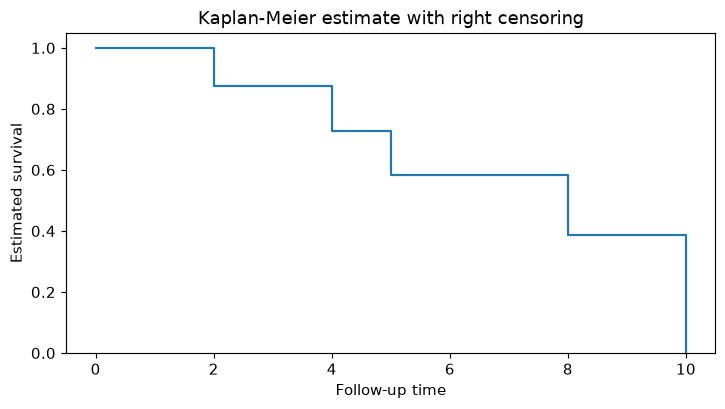

In [2]:
time=np.array([2.,3.,4.,5.,6.,8.,9.,10.]);event=np.array([1,0,1,1,0,1,0,1])
survival=1.;event_times=[];survivals=[]
for t in np.unique(time[event==1]):
    risk=np.sum(time>=t);deaths=np.sum((time==t)&(event==1));survival*=1-deaths/risk
    event_times.append(t);survivals.append(survival)
    print("t/risk/events/S:",t,risk,deaths,survival)
fig,ax=plt.subplots();ax.step(np.r_[0,event_times],np.r_[1,survivals],where="post")
ax.set(title="Kaplan-Meier estimate with right censoring",xlabel="Follow-up time",ylabel="Estimated survival",ylim=(0,1.05))
fig.tight_layout();plt.show()

## 3. Cox Proportional Hazards Model

The Cox model uses h(t|x)=h₀(t)exp(xᵀβ), leaving baseline hazard unspecified. exp(βⱼ) is a conditional hazard ratio per unit xⱼ, assumed constant over time; it is not a risk ratio or a causal effect by default. Partial likelihood compares each event's covariate score with its current risk set. Tied events require a method such as Breslow or Efron.

**Example:** fit one covariate with distinct event times using partial log-likelihood. Real analyses need proportional-hazards diagnostics, suitable censoring assumptions, uncertainty estimates, and possibly time-varying coefficients. A successful optimizer alone establishes none of those.

In [3]:
x=np.array([0.,1.,.5,1.5,-.5,.8,-.8,.3])
def cox_nll(beta):
    eta=x*float(np.asarray(beta).ravel()[0]);value=0.
    for i in np.flatnonzero(event):value+=eta[i]-special.logsumexp(eta[time>=time[i]])
    return -value
cox=optimize.minimize(cox_nll,[0.],method="BFGS")
print("Illustrative Cox coefficient / hazard ratio:",cox.x[0],np.exp(cox.x[0]))

Illustrative Cox coefficient / hazard ratio: 0.8698803322726467 2.386625234417076


## 4. Causal Inference, Confounding and Mediation

Causal inference targets interventions or potential outcomes, not merely P(Y|X). For binary treatment A, ATE=E[Y(1)−Y(0)]. Identification from observational data often needs consistency (well-defined treatment), conditional exchangeability (no unmeasured confounding given chosen covariates), and positivity (both treatments possible in relevant covariate strata), plus an appropriate interference assumption.

A confounder opens a noncausal exposure-outcome path; a mediator lies on a treatment-outcome pathway. Adjusting for a mediator changes the target from a total effect and can introduce bias under further structures. Colliders should not be adjusted merely because they correlate with both variables. Draw and justify causal assumptions rather than select controls solely by p-values.

## 5. Propensity Score Matching

The propensity e(x)=P(A=1|X=x) summarizes treatment assignment given measured covariates. Matching compares treated/control units with similar scores or covariates, checking overlap and balance. It does not balance unmeasured confounders automatically, and poor overlap can force extrapolation. With-replacement matching and different weighting schemes target different populations, often ATT rather than ATE.

**Worked example:** use the known synthetic assignment propensity to illustrate inverse-probability ATE weighting and a nearest-propensity ATT match. In applications propensity is estimated without using outcomes to optimize a favorable effect, and balance/uncertainty need careful assessment.

In [4]:
n=1000;confounder=rng.normal(size=n);propensity=special.expit(.6*confounder)
treatment=rng.binomial(1,propensity);outcome=2*treatment+confounder+rng.normal(size=n)
iptw=np.mean(treatment*outcome/propensity-(1-treatment)*outcome/(1-propensity))
treated=np.flatnonzero(treatment);controls=np.flatnonzero(1-treatment)
matched=np.array([controls[np.argmin(np.abs(propensity[controls]-propensity[i]))] for i in treated])
att=np.mean(outcome[treated]-outcome[matched])
print("Oracle-propensity IPW ATE:",iptw,"matched ATT:",att,"synthetic effect:",2.)

Oracle-propensity IPW ATE: 2.0537550816517873 matched ATT: 2.0758893184087164 synthetic effect: 2.0


## 6. Difference-in-Differences

DiD compares treated-group before/after change with control-group change. Identification needs a parallel untreated-trends assumption for the target comparison, plus no anticipation and appropriate stable composition/interference conditions. Similar pre-trends can support but do not prove parallel counterfactual trends; a nonsignificant pretrend test is not proof.

A 2×2 estimate is (treated_after−treated_before)−(control_after−control_before). More periods, staggered adoption, heterogeneous effects, and serial dependence complicate common two-way fixed-effects analyses; use a method matched to the design.

## 7. Instrumental Variables

An instrument Z shifts treatment/exposure while identifying an effect only under assumptions such as relevance, independence from outcome confounders, and exclusion of a direct outcome path. For binary encouragement designs, monotonicity and other conditions identify a local average treatment effect among compliers, not automatically a population ATE.

For a simple linear single-instrument model, the ratio Cov(Z,Y)/Cov(Z,A) illustrates IV. Weak instruments create unstable estimates; empirical association cannot establish exclusion. Domain reasoning and design are indispensable.

In [5]:
control_before,control_after=10.,12.;treated_before,treated_after=11.,16.
print("2x2 DiD:",(treated_after-treated_before)-(control_after-control_before))
n=4000;z=rng.normal(size=n);u=rng.normal(size=n)
exposure=.8*z+.6*u+rng.normal(size=n);response=2*exposure+u+rng.normal(size=n)
iv=np.cov(z,response,ddof=0)[0,1]/np.cov(z,exposure,ddof=0)[0,1]
ols=np.cov(exposure,response,ddof=0)[0,1]/exposure.var()
print("Synthetic linear IV:",iv,"confounded OLS:",ols,"true slope:",2.)

2x2 DiD: 3.0
Synthetic linear IV: 2.004840722497014 confounded OLS: 2.3103400398572402 true slope: 2.0


## AI/ML application and interpretation

Survival and causal ML support churn timing, treatment-policy evaluation, and counterfactual decisions, but require collection and identification assumptions beyond ordinary prediction. Use suitable uncertainty estimates, sensitivity analysis, external validation, and subject-matter review before applying substantive effect claims. The synthetic calculations demonstrate mechanics rather than validate any real-world intervention.

## Practice

1. Why is a censored time not an observed event time?
2. Is a hazard ratio the same as an interval risk ratio?
3. What can propensity matching not guarantee?
4. State DiD's central counterfactual assumption.
5. Why is an instrument's association with exposure insufficient for causal identification?

## Solutions

1. It gives a lower bound on survival/event time under right censoring, not the exact event occurrence.
2. No. It compares instantaneous rates conditional on survival/model covariates, not accumulated interval probabilities.
3. Removal of unmeasured confounding, adequate overlap, or a correct treatment/outcome definition.
4. Parallel untreated trends for the treated and comparison groups under the specified design.
5. Exclusion and independence from outcome confounders are additional substantive assumptions; weak relevance also creates statistical problems.

## Final review: Modules 5–9

You should now distinguish sampling design, estimator uncertainty, model assumptions, predictive performance, numerical approximation, and causal identification. Choose methods by their target and assumptions; do not treat a p-value, optimizer success, posterior normalization, or attractive plot as a complete validation.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](../README.md).